<a href="https://colab.research.google.com/github/markammonika56-spec/movie-rating-analyzer/blob/main/Movie_Rating_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Step 1: Create movie data
data = {
    "Movie": [
        "Inception", "Titanic", "Interstellar",
        "Dangal", "Sholay", "Avatar",
        "Jawan", "3 Idiots", "The Dark Knight", "Frozen"
    ],

    "Genre": [
        "SciFi", "Romance", "SciFi", "Drama",
        "Action", "SciFi", "Action", "Comedy",
        "Action", "Animation"
    ],

    "Rating": [
        8.8, 7.9, 8.6, 8.4, 9.0,
        7.8, 7.5, 8.4, 9.0, 7.4
    ]
}

# Step 2: Convert data into table
movies = pd.DataFrame(data)

# Step 3: Save data into CSV file
movies.to_csv("movies.csv", index=False)

print("CSV file created successfully!")

# Step 4: Read the CSV file
new_movies = pd.read_csv("movies.csv")

print("\nMovie Dataset:")
print(new_movies)

CSV file created successfully!

Movie Dataset:
             Movie      Genre  Rating
0        Inception      SciFi     8.8
1          Titanic    Romance     7.9
2     Interstellar      SciFi     8.6
3           Dangal      Drama     8.4
4           Sholay     Action     9.0
5           Avatar      SciFi     7.8
6            Jawan     Action     7.5
7         3 Idiots     Comedy     8.4
8  The Dark Knight     Action     9.0
9           Frozen  Animation     7.4


In [ ]:

import pandas as pd

test_data = {
    "Movie": ["Inception", "Titanic", "Dangal", "Avatar", None],
    "Genre": ["SciFi", "Romance", "Drama", "SciFi", "Action"],
    "Rating": [8.8, 11, "abc", 7.8, 8.5]
}

test_movies = pd.DataFrame(test_data)

print(test_movies)

       Movie    Genre Rating
0  Inception    SciFi    8.8
1    Titanic  Romance     11
2     Dangal    Drama    abc
3     Avatar    SciFi    7.8
4       None   Action    8.5


In [ ]:

# Check missing values
print("Missing Values:")
print(test_movies.isnull().sum())

# Convert ratings into numbers
test_movies["Rating"] = pd.to_numeric(
    test_movies["Rating"], errors="coerce"
)

# Check invalid ratings
invalid_ratings = test_movies[
    (test_movies["Rating"] < 0) |
    (test_movies["Rating"] > 10) |
    (test_movies["Rating"].isnull())
]

print("\nInvalid Data:")
print(invalid_ratings)

Missing Values:
Movie     1
Genre     0
Rating    0
dtype: int64

Invalid Data:
     Movie    Genre  Rating
1  Titanic  Romance    11.0
2   Dangal    Drama     NaN


In [ ]:

# Remove rows with missing Movie or Genre
clean_movies = test_movies.dropna(
    subset=["Movie", "Genre", "Rating"]
)

# Keep ratings between 0 and 10
clean_movies = clean_movies[
    (clean_movies["Rating"] >= 0) &
    (clean_movies["Rating"] <= 10)
]

print("Clean Movie Dataset:")
print(clean_movies)

print("\nTotal valid movies:", len(clean_movies))

Clean Movie Dataset:
       Movie  Genre  Rating
0  Inception  SciFi     8.8
3     Avatar  SciFi     7.8

Total valid movies: 2


In [ ]:

# Read our original movie dataset
movies = pd.read_csv("movies.csv")

# Calculate average rating
average_rating = movies["Rating"].mean()

print("Average Movie Rating:", round(average_rating, 2))

Average Movie Rating: 8.28


In [ ]:

# Find the highest rated movie
highest_rating = movies["Rating"].max()

top_movies = movies[
    movies["Rating"] == highest_rating
]

print("Highest Rating:", highest_rating)
print("Top Rated Movie:")
print(top_movies)

Highest Rating: 9.0
Top Rated Movie:
             Movie   Genre  Rating
4           Sholay  Action     9.0
8  The Dark Knight  Action     9.0


In [ ]:

# Find the lowest rated movie
lowest_rating = movies["Rating"].min()

lowest_movies = movies[
    movies["Rating"] == lowest_rating
]

print("Lowest Rating:", lowest_rating)
print("Lowest Rated Movie:")
print(lowest_movies)

Lowest Rating: 7.4
Lowest Rated Movie:
    Movie      Genre  Rating
9  Frozen  Animation     7.4


In [ ]:
# Calculate average rating of each genre
genre_average = movies.groupby("Genre")["Rating"].mean()

print("Genre-wise Average Ratings:")
print(genre_average)

Genre-wise Average Ratings:
Genre
Action       8.5
Animation    7.4
Comedy       8.4
Drama        8.4
Romance      7.9
SciFi        8.4
Name: Rating, dtype: float64


In [ ]:
genre_average = movies.groupby("Genre")["Rating"].mean()

print(genre_average)

Genre
Action       8.5
Animation    7.4
Comedy       8.4
Drama        8.4
Romance      7.9
SciFi        8.4
Name: Rating, dtype: float64


In [ ]:
best_genre = genre_average.idxmax()
highest_genre_rating = genre_average.max()

print("Best Performing Genre:", best_genre)
print("Average Rating:", round(highest_genre_rating, 2))

Best Performing Genre: Action
Average Rating: 8.5


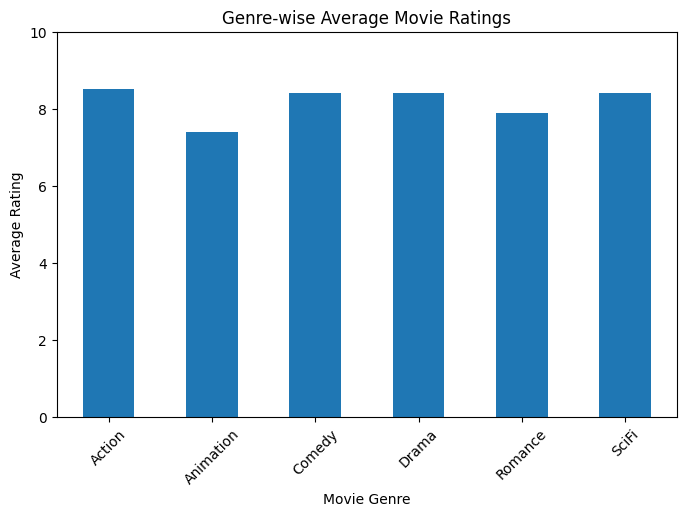

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

genre_average.plot(kind="bar")

plt.title("Genre-wise Average Movie Ratings")
plt.xlabel("Movie Genre")
plt.ylabel("Average Rating")

plt.ylim(0, 10)
plt.xticks(rotation=45)

plt.show()

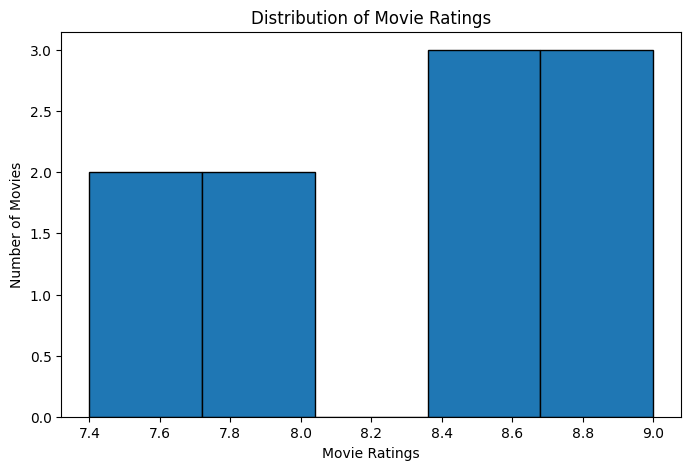

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(movies["Rating"], bins=5, edgecolor="black")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Movie Ratings")
plt.ylabel("Number of Movies")

plt.show()

In [ ]:
# Convert ratings into numbers
movies["Rating"] = pd.to_numeric(
    movies["Rating"], errors="coerce"
)

# Remove rows with missing values
movies = movies.dropna(
    subset=["Movie", "Genre", "Rating"]
)

# Keep ratings between 0 and 10
movies = movies[
    (movies["Rating"] >= 0) &
    (movies["Rating"] <= 10)
]

# Reset row numbers
movies = movies.reset_index(drop=True)

print("Data Cleaning Completed!")
print(movies)

Data Cleaning Completed!
             Movie      Genre  Rating
0        Inception      SciFi     8.8
1          Titanic    Romance     7.9
2     Interstellar      SciFi     8.6
3           Dangal      Drama     8.4
4           Sholay     Action     9.0
5           Avatar      SciFi     7.8
6            Jawan     Action     7.5
7         3 Idiots     Comedy     8.4
8  The Dark Knight     Action     9.0
9           Frozen  Animation     7.4


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

menu = widgets.Dropdown(
    options=[
        ("1. Show All Movies", "1"),
        ("2. Average Rating", "2"),
        ("3. Highest Rated Movie", "3"),
        ("4. Lowest Rated Movie", "4"),
        ("5. Genre-wise Average", "5"),
        ("6. Best Performing Genre", "6"),
        ("7. Bar Chart", "7"),
        ("8. Histogram", "8"),
        ("9. Exit", "9")
    ],
    description="Menu:"
)

run_button = widgets.Button(description="Run Option")
output = widgets.Output()

def run_choice(button):
    with output:
        clear_output()
        choice = menu.value

        if choice == "1":
            print("All Movies:")
            display(movies)

        elif choice == "2":
            print("Average Rating:", round(movies["Rating"].mean(), 2))

        elif choice == "3":
            highest = movies["Rating"].max()
            print(movies[movies["Rating"] == highest])

        elif choice == "4":
            lowest = movies["Rating"].min()
            print(movies[movies["Rating"] == lowest])

        elif choice == "5":
            print(movies.groupby("Genre")["Rating"].mean())

        elif choice == "6":
            genre_average = movies.groupby("Genre")["Rating"].mean()
            print("Best Performing Genre:")
            print(genre_average[genre_average == genre_average.max()])

        elif choice == "7":
            genre_average = movies.groupby("Genre")["Rating"].mean()
            genre_average.plot(kind="bar")
            plt.title("Average Rating by Genre")
            plt.xlabel("Genre")
            plt.ylabel("Average Rating")
            plt.show()

        elif choice == "8":
            plt.hist(movies["Rating"], bins=5, edgecolor="black")
            plt.title("Movie Rating Distribution")
            plt.xlabel("Rating")
            plt.ylabel("Number of Movies")
            plt.show()

        elif choice == "9":
            print("Thank you for using Movie Rating Analyzer!")

run_button.on_click(run_choice)

display(menu, run_button, output)

Dropdown(description='Menu:', options=(('1. Show All Movies', '1'), ('2. Average Rating', '2'), ('3. Highest R…

Button(description='Run Option', style=ButtonStyle())

Output()

In [ ]:

import pandas as pd

# TEST CASE 1: Normal Movie Data
print("TEST CASE 1: Normal Data")

normal_data = movies.copy()
print("Total Movies:", len(normal_data))
print("Average Rating:", round(normal_data["Rating"].mean(), 2))
print("Test Passed")


# TEST CASE 2: Single Movie
print("\nTEST CASE 2: Single Movie")

single_movie = pd.DataFrame({
    "Movie": ["Test Movie"],
    "Genre": ["Comedy"],
    "Rating": [8.5]
})

print(single_movie)
print("Average Rating:", single_movie["Rating"].mean())
print("Test Passed")


# TEST CASE 3: Invalid Data
print("\nTEST CASE 3: Invalid Data")

invalid_data = pd.DataFrame({
    "Movie": ["Valid Movie", "Missing Rating",
              "High Rating", "Negative Rating", "Text Rating"],
    "Genre": ["Drama", "Action", "Comedy", "Drama", "Action"],
    "Rating": [8.0, None, 11, -2, "abc"]
})

invalid_data["Rating"] = pd.to_numeric(
    invalid_data["Rating"], errors="coerce"
)

clean_data = invalid_data.dropna(subset=["Rating"])

clean_data = clean_data[
    (clean_data["Rating"] >= 0) &
    (clean_data["Rating"] <= 10)
]

print("Original Records:", len(invalid_data))
print("Valid Records:", len(clean_data))
print("Invalid Records Removed:",
      len(invalid_data) - len(clean_data))
print(clean_data)
print("Test Passed")


# TEST CASE 4: Genre-wise Analysis
print("\nTEST CASE 4: Genre-wise Analysis")

genre_result = movies.groupby("Genre")["Rating"].mean()

print(genre_result)
print("Test Passed")

print("\nAll Test Cases Completed Successfully!")

TEST CASE 1: Normal Data
Total Movies: 10
Average Rating: 8.28
Test Passed

TEST CASE 2: Single Movie
        Movie   Genre  Rating
0  Test Movie  Comedy     8.5
Average Rating: 8.5
Test Passed

TEST CASE 3: Invalid Data
Original Records: 5
Valid Records: 1
Invalid Records Removed: 4
         Movie  Genre  Rating
0  Valid Movie  Drama     8.0
Test Passed

TEST CASE 4: Genre-wise Analysis
Genre
Action       8.5
Animation    7.4
Comedy       8.4
Drama        8.4
Romance      7.9
SciFi        8.4
Name: Rating, dtype: float64
Test Passed

All Test Cases Completed Successfully!
